# Лабораторная работа №12: Генерация синтетического датасета для VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Сгенерировать спецификации сцен и изображения.
- Проверить/отфильтровать VLM и embeddings.
- Сравнить real/synthetic mixtures.


## Теоретическая часть

Корректный pipeline: scene specification → renderer/diffusion → VLM verification → filtering → downstream evaluation. Synthetic test не заменяет реальный test; provenance каждого примера обязателен.


### Математическая постановка

Для смеси $D_\alpha=(1-\alpha)D_{real}+\alpha D_{syn}$ исследуется $Q(\alpha)$ на фиксированном реальном test set. Duplicate filtering использует cosine similarity embeddings.


### Материалы

- [BlenderProc](https://github.com/DLR-RM/BlenderProc)
- [Diffusers](https://huggingface.co/docs/diffusers/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

В полном режиме обязательны реальный test-корпус, реальная VLM-проверка синтетики и обучение нескольких downstream-моделей. Процедурный renderer позволяет воспроизводить provenance, но синтетические изображения никогда не называются «реальными». Реальные фотографии и опубликованные метки 2/3 объектов берутся из человечески проверенных validation/test PixMo-Count (ODC-BY-1.0 для датасета; права исходных Flickr-фотографий могут отличаться). Ноутбук автоматически скачивает subset и записывает `data/lab12/real_manifest.jsonl`. Это междоменная оценка переноса счёта геометрических фигур на реальные объекты, а не тест распознавания кругов/квадратов. FAST_DEV_RUN проверяет только renderer и инварианты, не создаёт метрики качества.

In [39]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

VLM_LOADER = "\n# Одна и та же квантованная модель и интерфейс используются для сравниваемых запусков.\n# В Colab предварительно: %pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets\nimport torch\nfrom PIL import Image\nfrom transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig\nMODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')\nassert torch.cuda.is_available(), 'Требуется GPU для реального VLM-инференса; CPU smoke проверяет только данные и код.'\nquant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16)\nprocessor = AutoProcessor.from_pretrained(MODEL_ID)\nmodel = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, device_map='auto').eval()\ndef infer_image(path, prompt, adapter=None):\n    messages = [{'role':'user','content':[{'type':'image','image':Image.open(path).convert('RGB')},{'type':'text','text':prompt}]}]\n    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)\n    inputs = processor(text=[text], images=[Image.open(path).convert('RGB')], return_tensors='pt').to(model.device)\n    with torch.no_grad(): generated = model.generate(**inputs, max_new_tokens=96, do_sample=False)\n    return processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()\n"

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Геометрический рендерер

*Вес: 1 балл.*

**Постановка.** Этап «геометрический рендерер» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте рендерер цветных фигур без перекрытий с фиксированными координатами.
2. Сохраните и предъявите функция render и словарь палитры.

**Результат.** функция render и словарь палитры.

**Критерий принятия.** Задание считается принятым, если функция render и словарь палитры получены из фактических входов этого этапа и доступны для проверки.

In [40]:
# Реализуйте это задание по постановке выше.
# Артефакт: функция render и словарь палитры
from PIL import Image, ImageDraw
import math

PALETTE = {
    "red": (220, 55, 55),
    "blue": (55, 105, 220),
    "green": (55, 165, 95),
    "yellow": (245, 195, 55),
    "purple": (145, 85, 190),
    "orange": (235, 130, 45),
}
CANVAS_SIZE = (256, 256)
BACKGROUND = (248, 248, 245)

def render(spec, size=CANVAS_SIZE):
    """Рендерит сцену из spec без перекрытия фигур."""
    image = Image.new("RGB", size, BACKGROUND)
    draw = ImageDraw.Draw(image)
    for obj in spec["objects"]:
        x, y, radius = int(obj["x"]), int(obj["y"]), int(obj["size"])
        color = PALETTE[obj["color"]]
        box = (x-radius, y-radius, x+radius, y+radius)
        if obj["shape"] == "circle":
            draw.ellipse(box, fill=color, outline=(35,35,35), width=2)
        elif obj["shape"] == "square":
            draw.rectangle(box, fill=color, outline=(35,35,35), width=2)
        elif obj["shape"] == "triangle":
            pts = [(x, y-radius), (x-radius, y+radius), (x+radius, y+radius)]
            draw.polygon(pts, fill=color, outline=(35,35,35))
        else:
            raise ValueError(f"Неизвестная фигура: {obj['shape']}")
    return image

print("PALETTE =", PALETTE)
print("render готова:", render.__name__)

PALETTE = {'red': (220, 55, 55), 'blue': (55, 105, 220), 'green': (55, 165, 95), 'yellow': (245, 195, 55), 'purple': (145, 85, 190), 'orange': (235, 130, 45)}
render готова: render


### Пространство визуальных сцен

*Вес: 1 балл.*

**Постановка.** Этап «пространство визуальных сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сгенерируйте воспроизводимые сочетания формы, цвета и числа объектов.
2. Сохраните и предъявите воспроизводимые спецификации фигур и количества.

**Результат.** воспроизводимые спецификации фигур и количества.

**Критерий принятия.** Задание считается принятым, если воспроизводимые спецификации фигур и количества получены из фактических входов этого этапа и доступны для проверки.

In [41]:
# Реализуйте это задание по постановке выше.
# Артефакт: воспроизводимые спецификации фигур и количества
SHAPES = ("circle", "square", "triangle")
COLORS = tuple(PALETTE)
IMAGE_SIZE = CANVAS_SIZE

def make_scene_specs(n=120, seed=SEED):
    """Воспроизводимые сцены; классы сбалансированы между 2 и 3 объектами."""
    rng = random.Random(seed)
    specs = []
    centers = [(64,64), (192,64), (64,192), (192,192), (128,128)]
    for i in range(n):
        count = 2 + (i % 2)
        chosen = rng.sample(centers, count)
        objects = []
        for x, y in chosen:
            objects.append({
                "shape": rng.choice(SHAPES),
                "color": rng.choice(COLORS),
                "x": x, "y": y, "size": rng.randint(19, 25)
            })
        specs.append({
            "id": f"synthetic-{i:04d}", "seed": seed, "index": i,
            "count": count, "objects": objects
        })
    rng.shuffle(specs)
    return specs

scene_specs = make_scene_specs(240, SEED)
assert {s["count"] for s in scene_specs} == {2, 3}
print(f"Создано спецификаций: {len(scene_specs)}")
print("Пример:", scene_specs[0])

Создано спецификаций: 240
Пример: {'id': 'synthetic-0218', 'seed': 42, 'index': 218, 'count': 2, 'objects': [{'shape': 'triangle', 'color': 'orange', 'x': 64, 'y': 64, 'size': 22}, {'shape': 'square', 'color': 'purple', 'x': 128, 'y': 128, 'size': 25}]}


### Изображения и вопросы

*Вес: 1 балл.*

**Постановка.** Этап «изображения и вопросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения, вопрос и ответ для каждой сцены.
2. Сохраните и предъявите файлы изображений и связанные с ними ответы.

**Результат.** файлы изображений и связанные с ними ответы.

**Критерий принятия.** Задание считается принятым, если файлы изображений и связанные с ними ответы получены из фактических входов этого этапа и доступны для проверки.

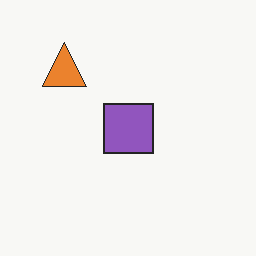

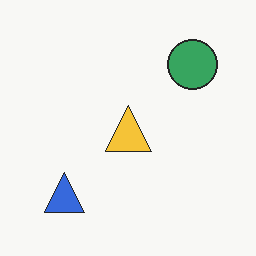

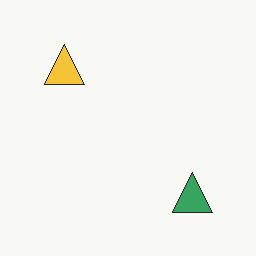

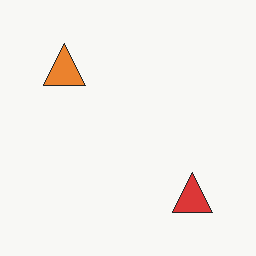

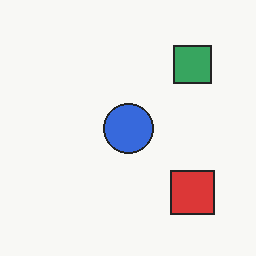

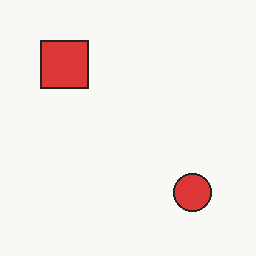

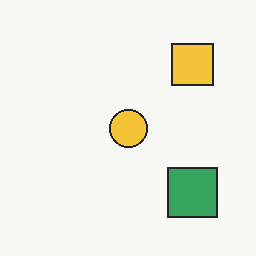

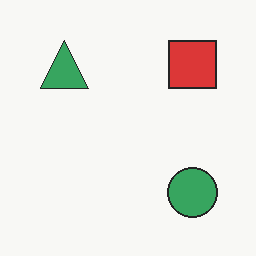

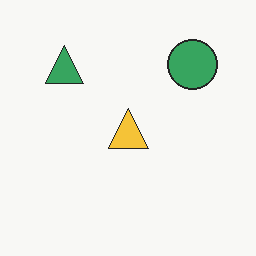

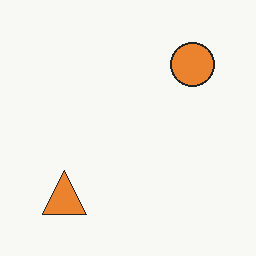

Изображения: 240 Каталог: data/lab12/synthetic


In [42]:
# Реализуйте это задание по постановке выше.
# Артефакт: файлы изображений и связанные с ними ответы
from PIL import Image
from IPython.display import display

SYNTHETIC_DIR = Path("data/lab12/synthetic")
SYNTHETIC_DIR.mkdir(parents=True, exist_ok=True)
synthetic_records = []
for spec in scene_specs:
    image_path = SYNTHETIC_DIR / f'{spec["id"]}.png'
    render(spec).save(image_path)
    synthetic_records.append({
        "id": spec["id"], "image": str(image_path.resolve()),
        "question": "How many geometric objects are visible? Answer with one integer.",
        "answer": str(spec["count"]), "count": spec["count"],
        "spec": spec, "split": "synthetic", "provenance": "procedural_pillow_renderer"
    })
for spec in scene_specs[:10]:
    display(render(spec))
print("Изображения:", len(synthetic_records), "Каталог:", SYNTHETIC_DIR)

### Происхождение синтетических данных

*Вес: 1 балл.*

**Постановка.** Этап «происхождение синтетических данных» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Зафиксируйте seed, спецификацию, пути и provenance в манифесте.
2. Сохраните и предъявите artifacts/synthetic_manifest.jsonl.

**Результат.** artifacts/synthetic_manifest.jsonl.

**Критерий принятия.** Задание считается принятым, если artifacts/synthetic_manifest.jsonl получены из фактических входов этого этапа и доступны для проверки.

In [43]:
# Реализуйте это задание по постановке выше.
# Артефакт: artifacts/synthetic_manifest.jsonl
import hashlib
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

manifest_path = ARTIFACTS / "synthetic_manifest.jsonl"
with manifest_path.open("w", encoding="utf-8") as f:
    for rec in synthetic_records:
        row = {**rec, "seed": SEED, "image_sha256": sha256_file(rec["image"])}
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
print("Сохранён:", manifest_path, "записей:", len(synthetic_records))

Сохранён: artifacts/synthetic_manifest.jsonl записей: 240


### Ответы VLM и визуальная дедупликация

*Вес: 1 балл.*

**Постановка.** Этап «ответы vlm и визуальная дедупликация» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Спросите реальную VLM о числе фигур и найдите дубли по хешу пикселей.
2. Сохраните и предъявите artifacts/verification.jsonl с реальными ответами VLM.

**Результат.** artifacts/verification.jsonl с реальными ответами VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/verification.jsonl с реальными ответами VLM получены из фактических входов этого этапа и доступны для проверки.

In [47]:
%pip install -U bitsandbytes>=0.46.1
from transformers.utils import is_bitsandbytes_available
is_bitsandbytes_available.cache_clear()


In [49]:
# Реализуйте это задание по постановке выше.
# Артефакт: artifacts/verification.jsonl с реальными ответами VLM
# Реальная VLM-проверка. Модель загружается один раз и отвечает для каждой сцены.
if FAST_DEV_RUN:
    raise RuntimeError("FAST_DEV_RUN=True: это только smoke-test, реальная VLM-проверка не выполняется.")
exec(VLM_LOADER)
import re
verification = []
for i, rec in enumerate(synthetic_records, 1):
    raw = infer_image(rec["image"], rec["question"])
    match = re.search(r"\b([0-9]+)\b", raw)
    predicted = match.group(1) if match else None
    verification.append({
        "id": rec["id"], "image": rec["image"], "gold": rec["answer"],
        "vlm_raw": raw, "vlm_answer": predicted,
        "agrees": predicted == rec["answer"],
        "image_sha256": sha256_file(rec["image"])
    })
    if i % 10 == 0:
        print(f"Проверено {i}/{len(synthetic_records)}")
with (ARTIFACTS / "verification.jsonl").open("w", encoding="utf-8") as f:
    for row in verification:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
print("Сохранён artifacts/verification.jsonl; согласие:", sum(x["agrees"] for x in verification), "/", len(verification))

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Проверено 10/240
Проверено 20/240
Проверено 30/240
Проверено 40/240
Проверено 50/240
Проверено 60/240
Проверено 70/240
Проверено 80/240
Проверено 90/240
Проверено 100/240
Проверено 110/240
Проверено 120/240
Проверено 130/240
Проверено 140/240
Проверено 150/240
Проверено 160/240
Проверено 170/240
Проверено 180/240
Проверено 190/240
Проверено 200/240
Проверено 210/240
Проверено 220/240
Проверено 230/240
Проверено 240/240
Сохранён artifacts/verification.jsonl; согласие: 229 / 240


### Отбор согласованных пар

*Вес: 1 балл.*

**Постановка.** Этап «отбор согласованных пар» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите только изображения с согласованным ответом и без дублей.
2. Сохраните и предъявите artifacts/accepted.jsonl после проверки ответов.

**Результат.** artifacts/accepted.jsonl после проверки ответов.

**Критерий принятия.** Задание считается принятым, если artifacts/accepted.jsonl после проверки ответов получены из фактических входов этого этапа и доступны для проверки.

In [50]:
# Реализуйте это задание по постановке выше.
# Артефакт: artifacts/accepted.jsonl после проверки ответов
# Принимаем только согласованные с VLM примеры и удаляем дубли по хешу пикселей.
seen = set()
accepted = []
for rec, check in zip(synthetic_records, verification):
    digest = sha256_file(rec["image"])
    if check["agrees"] and digest not in seen:
        seen.add(digest)
        accepted.append({**rec, "image_sha256": digest,
                         "verification_raw": check["vlm_raw"],
                         "filter": "VLM_answer_agrees_and_unique_sha256"})
accepted_path = ARTIFACTS / "accepted.jsonl"
with accepted_path.open("w", encoding="utf-8") as f:
    for row in accepted:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
print(f"Принято {len(accepted)}/{len(synthetic_records)} сцен")
if len(accepted) < 24:
    raise RuntimeError("Недостаточно принятых синтетических примеров для четырёх смесей; увеличьте n в cell 11.")

Принято 229/240 сцен


### Независимый набор реальных изображений

*Вес: 1 балл.*

**Постановка.** Этап «независимый набор реальных изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Скачайте PixMo-Count validation для обучения и официальный test для отложенной оценки; проверьте метки и отсутствие общих ID/изображений.
2. Сохраните и предъявите проверенный real train/test manifest с источником, split и контрольными суммами.

**Результат.** проверенный real train/test manifest с источником, split и контрольными суммами.

**Критерий принятия.** Задание считается принятым, если проверенный real train/test manifest получены из фактических входов этого этапа и доступны для проверки.

In [51]:
# Реализуйте это задание по постановке выше.
# Артефакт: проверенный real train/test manifest
from open_real_scenes import load_real_scenes

real_records = load_real_scenes(root="data/lab12/real", train_size=36, test_size=12)
real_train = real_records[:36]
real_test = real_records[36:]
print (len(real_records))
assert len(real_train) == 36 and len(real_test) == 12
assert {r["answer"] for r in real_train} == {"2", "3"}
assert {r["answer"] for r in real_test} == {"2", "3"}
assert not ({r["image_sha256"] for r in real_train} & {r["image_sha256"] for r in real_test})
save_json("real_manifest_summary.json", {
"source": "allenai/pixmo-count", "train_source_split": "validation",
"test_source_split": "test", "train_main": len(real_train),"test": len(real_test),
"test_is_held_out": True
})
print("Real train:", len(real_train),  "real test:", len(real_test))
print("Manifest:", "data/lab12/real/real_manifest.jsonl")

48
Real train: 36 real test: 12
Manifest: data/lab12/real/real_manifest.jsonl


### Признаки реальных и синтетических сцен

*Вес: 1 балл.*

**Постановка.** Этап «признаки реальных и синтетических сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите одинаковые замороженные признаки ResNet18 для real train, synthetic и real test.
2. Сохраните и предъявите замороженные признаки ResNet18 для трёх наборов.

**Результат.** замороженные признаки ResNet18 для трёх наборов.

**Критерий принятия.** Задание считается принятым, если замороженные признаки ResNet18 для трёх наборов получены из фактических входов этого этапа и доступны для проверки.

In [52]:
# Реализуйте это задание по постановке выше.
# Артефакт: замороженные признаки ResNet18 для трёх наборов
# Замороженный ResNet18: один и тот же extractor и preprocessing для всех наборов.
import torch
from PIL import Image
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import Dataset, DataLoader

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()
resnet = resnet18(weights=weights)
feature_extractor = torch.nn.Sequential(*list(resnet.children())[:-1]).to(DEVICE).eval()
for p in feature_extractor.parameters():
    p.requires_grad = False

def extract_features(records, batch_size=16):
    feats, labels = [], []
    with torch.no_grad():
        for start in range(0, len(records), batch_size):
            batch = records[start:start+batch_size]
            tensors = torch.stack([preprocess(Image.open(r["image"]).convert("RGB")) for r in batch]).to(DEVICE)
            z = feature_extractor(tensors).flatten(1).cpu().numpy()
            feats.append(z)
            labels.extend(int(r.get("answer", r.get("count"))) for r in batch)
    return np.concatenate(feats), np.asarray(labels, dtype=np.int64)

X_real, y_real = extract_features(real_train)
X_syn, y_syn = extract_features(accepted)
X_test, y_test = extract_features(real_test)
np.savez_compressed(ARTIFACTS / "frozen_resnet18_features.npz",
                    X_real=X_real, y_real=y_real, X_syn=X_syn, y_syn=y_syn,
                    X_test=X_test, y_test=y_test)
print("Features:", X_real.shape, X_syn.shape, X_test.shape)

Features: (36, 512) (229, 512) (12, 512)


### Обучение на смесях

*Вес: 1 балл.*

**Постановка.** Этап «обучение на смесях» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. При постоянном бюджете train обучите классификаторы с четырьмя долями синтетики.
2. Сохраните и предъявите результаты классификаторов при четырёх долях синтетики.

**Результат.** результаты классификаторов при четырёх долях синтетики.

**Критерий принятия.** Задание считается принятым, если результаты классификаторов при четырёх долях синтетики получены из фактических входов этого этапа и доступны для проверки.

In [53]:
# Реализуйте это задание по постановке выше.
# Артефакт: результаты классификаторов при четырёх долях синтетики
# Фиксированный бюджет: 24 обучающих примера в каждом запуске.
# alpha — доля синтетики; остальные места заполняются реальными validation-примерами.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

ALPHAS = [0.0, 0.25, 0.5, 0.75]
TRAIN_BUDGET = 36
rng = np.random.default_rng(SEED)
mixture_models = {}
mixture_summary = []
for alpha in ALPHAS:
    n_syn = int(round(alpha * TRAIN_BUDGET))
    n_real = TRAIN_BUDGET - n_syn
    if n_syn > len(X_syn) or n_real > len(X_real):
        raise RuntimeError(f"Недостаточно данных для alpha={alpha}: real={n_real}, synthetic={n_syn}")
    real_idx = rng.choice(len(X_real), n_real, replace=False) if n_real else np.array([], dtype=int)
    syn_idx = rng.choice(len(X_syn), n_syn, replace=False) if n_syn else np.array([], dtype=int)
    X_mix = np.concatenate([X_real[real_idx], X_syn[syn_idx]], axis=0)
    y_mix = np.concatenate([y_real[real_idx], y_syn[syn_idx]], axis=0)
    model_mix = make_pipeline(StandardScaler(), LogisticRegression(C=1.0,max_iter=3000))
    model_mix.fit(X_mix, y_mix)
    mixture_models[alpha] = model_mix
    mixture_summary.append({"alpha": alpha, "n_real": n_real, "n_synthetic": n_syn,
                            "train_budget": len(y_mix)})
print(mixture_summary)

[{'alpha': 0.0, 'n_real': 36, 'n_synthetic': 0, 'train_budget': 36}, {'alpha': 0.25, 'n_real': 27, 'n_synthetic': 9, 'train_budget': 36}, {'alpha': 0.5, 'n_real': 18, 'n_synthetic': 18, 'train_budget': 36}, {'alpha': 0.75, 'n_real': 9, 'n_synthetic': 27, 'train_budget': 36}]


### Оценка на реальном тесте

*Вес: 1 балл.*

**Постановка.** Этап «оценка на реальном тесте» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Запишите предсказания и accuracy всех моделей только на реальном test.
2. Сохраните и предъявите mixture_results.json и predictions.jsonl.

**Результат.** mixture_results.json и predictions.jsonl.

**Критерий принятия.** Задание считается принятым, если mixture_results.json и predictions.jsonl получены из фактических входов этого этапа и доступны для проверки.

In [54]:
# Реализуйте это задание по постановке выше.
# Артефакт: mixture_results.json и predictions.jsonl
# Только реальный официальный test используется для итогового сравнения.
results = []
predictions = []
for alpha, clf in mixture_models.items():
    pred = clf.predict(X_test)
    acc = float(accuracy_score(y_test, pred))
    results.append({"alpha_synthetic": alpha, "accuracy_real_test": acc,
                    "n_test": int(len(y_test)), "train_budget": TRAIN_BUDGET})
    for i, (record, gold, guess) in enumerate(zip(real_test, y_test, pred)):
        predictions.append({"alpha_synthetic": alpha, "id": record["id"],
                            "image": record["image"], "gold": int(gold),
                            "prediction": int(guess), "correct": bool(gold == guess)})
save_json("mixture_results.json", results)
with (ARTIFACTS / "predictions.jsonl").open("w", encoding="utf-8") as f:
    for row in predictions:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
print(json.dumps(results, indent=2))
print("Сохранены artifacts/mixture_results.json и artifacts/predictions.jsonl")

[
  {
    "alpha_synthetic": 0.0,
    "accuracy_real_test": 0.5,
    "n_test": 12,
    "train_budget": 36
  },
  {
    "alpha_synthetic": 0.25,
    "accuracy_real_test": 0.4166666666666667,
    "n_test": 12,
    "train_budget": 36
  },
  {
    "alpha_synthetic": 0.5,
    "accuracy_real_test": 0.4166666666666667,
    "n_test": 12,
    "train_budget": 36
  },
  {
    "alpha_synthetic": 0.75,
    "accuracy_real_test": 0.5833333333333334,
    "n_test": 12,
    "train_budget": 36
  }
]
Сохранены artifacts/mixture_results.json и artifacts/predictions.jsonl


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [13]:
# Реализуйте творческое мини-исследование по постановке выше.
raise NotImplementedError("Реализуйте бонусное исследование")

NotImplementedError: Реализуйте бонусное исследование

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.